# AIML339 Galaxy Morphology Classification Comparison Project

donaldseth - 300665568

In [1]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import random
import copy
import time

from zipfile import ZipFile
from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms

In [2]:
# Set random seeds for reproducible experiments

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("Random seeds set to 42")

Random seeds set to 42


In [3]:
# Paths

LABELS_PATH = "training_solutions_rev1.csv"
IMAGES_PATH = "images_training_rev1.zip"

In [4]:
# Load Labels

labels = pd.read_csv(LABELS_PATH)

print("Total galaxies:", len(labels))
print("Number of classes:", len(labels.columns) - 1)

Total galaxies: 61578
Number of classes: 37


In [5]:
# Labels Subset

N_GALAXIES = 5000

labels_subset = labels.sample(
    n=N_GALAXIES,
    random_state=42
).copy()

labels_subset["filename"] = (
    labels_subset["GalaxyID"].astype(str)
)

labels_subset.head()

,GalaxyID,Class1.1,Class1.2,Class1.3,Class2.1,Class2.2,Class3.1,Class3.2,Class4.1,Class4.2,...,Class10.1,Class10.2,Class10.3,Class11.1,Class11.2,Class11.3,Class11.4,Class11.5,Class11.6,filename
30888,553402,0.018765,0.955090,0.026146,0.078768,0.876322,0.118995,0.757327,0.590601,0.285720,...,0.000000,0.136383,0.454219,0.193254,0.289966,0.000000,0.0,0.000000,0.107381,553402
23964,449744,0.806705,0.140380,0.052915,0.000000,0.140380,0.000000,0.140380,0.000000,0.140380,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,449744
53475,879640,0.662354,0.337646,0.000000,0.197076,0.140570,0.000000,0.140570,0.044101,0.096468,...,0.044101,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.044101,879640
16284,340485,0.092952,0.907048,0.000000,0.058283,0.848765,0.042052,0.806713,0.642360,0.206404,...,0.496498,0.134098,0.011765,0.000000,0.373704,0.010232,0.0,0.013647,0.244777,340485
60574,985545,0.144641,0.848689,0.006670,0.028017,0.820672,0.484659,0.336014,0.267777,0.552895,...,0.000000,0.219558,0.048219,0.000000,0.195449,0.000000,0.0,0.000000,0.072328,985545


In [6]:
# Collect from .zip file

with ZipFile(IMAGES_PATH, "r") as zip_file:
    
    images = []

    for galaxy_id in labels_subset["filename"]:
        filename = f"images_training_rev1/{galaxy_id}.jpg"
        image_data = zip_file.read(filename)

        image = Image.open(BytesIO(image_data))
        images.append(image.copy())

print("Images collected:", len(images))

Images collected: 5000


In [7]:
print(labels_subset.columns.tolist())

['GalaxyID', 'Class1.1', 'Class1.2', 'Class1.3', 'Class2.1', 'Class2.2', 'Class3.1', 'Class3.2', 'Class4.1', 'Class4.2', 'Class5.1', 'Class5.2', 'Class5.3', 'Class5.4', 'Class6.1', 'Class6.2', 'Class7.1', 'Class7.2', 'Class7.3', 'Class8.1', 'Class8.2', 'Class8.3', 'Class8.4', 'Class8.5', 'Class8.6', 'Class8.7', 'Class9.1', 'Class9.2', 'Class9.3', 'Class10.1', 'Class10.2', 'Class10.3', 'Class11.1', 'Class11.2', 'Class11.3', 'Class11.4', 'Class11.5', 'Class11.6', 'filename']


In [8]:
# Show the response probabilities for the first two Galaxy Zoo tasks
columns = [
    "Class1.1", "Class1.2", "Class1.3",
    "Class2.1", "Class2.2"
]

print(labels_subset[columns].head(10))

       Class1.1  Class1.2  Class1.3  Class2.1  Class2.2
30888  0.018765  0.955090  0.026146  0.078768  0.876322
23964  0.806705  0.140380  0.052915  0.000000  0.140380
53475  0.662354  0.337646  0.000000  0.197076  0.140570
16284  0.092952  0.907048  0.000000  0.058283  0.848765
60574  0.144641  0.848689  0.006670  0.028017  0.820672
17962  0.553336  0.374126  0.072539  0.000000  0.374126
19482  0.529935  0.379124  0.090940  0.000000  0.379124
24973  0.518825  0.456786  0.024389  0.029735  0.427051
59184  0.130019  0.869981  0.000000  0.000000  0.869981
32165  0.438559  0.512630  0.048810  0.068876  0.443754


In [9]:
# Keep galaxies whose most likely Task 01 response is not star/artifact
task1_columns = ["Class1.1", "Class1.2", "Class1.3"]

task1_labels = labels_subset[task1_columns].idxmax(axis=1)

classification_data = labels_subset[
    task1_labels != "Class1.3"
].copy()

# The three final classes follow our simplified decision tree
class_columns = ["Class1.1", "Class2.1", "Class2.2"]

class_names = [
    "Smooth",
    "Featured edge-on",
    "Featured not edge-on"
]

# Assign labels by following the Galaxy Zoo decision hierarchy:
# Task 01: smooth vs featured
# Task 02: if featured, edge-on vs not edge-on

classification_data["target"] = np.where(
    classification_data["Class1.1"] >= classification_data["Class1.2"],
    0,
    np.where(
        classification_data["Class2.1"] >= classification_data["Class2.2"],
        1,
        2
    )
)

# Check how many galaxies belong to each class
print("Total galaxies:", len(classification_data))

print(
    classification_data["target"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(class_names)))
)

Total galaxies: 4993
target
Smooth                  2147
Featured edge-on         540
Featured not edge-on    2306
Name: count, dtype: int64


**Label construction:** The three target classes were assigned by following the simplified Galaxy Zoo decision hierarchy. Task 01 determines whether a galaxy is smooth or featured. For featured galaxies, Task 02 determines whether they are edge-on or not edge-on. This approach was chosen because Task 02 response probabilities are weighted by the probability of reaching that task. An initial flat-label approach produced 109 differing assignments (2.18% of the dataset), so hierarchical label assignment was adopted for the final experiments.

In [10]:
# Check the corrected three-class label distribution
print("Total galaxies:", len(classification_data))

for class_id, class_name in enumerate(class_names):
    count = (classification_data["target"] == class_id).sum()
    print(f"{class_name}: {count}")

Total galaxies: 4993
Smooth: 2147
Featured edge-on: 540
Featured not edge-on: 2306


Dataset splitting: The initial prototype used a random 80/20 split followed by a training/validation split. For the final three-class experiments, stratified splitting is used to preserve the class distribution across training, validation and test sets.

In [11]:
# Split the corrected dataset into training, validation and test sets
# Stratification preserves the proportions of the three galaxy classes

train_val, test = train_test_split(
    classification_data,
    test_size=0.20,
    random_state=42,
    stratify=classification_data["target"]
)

train, validation = train_test_split(
    train_val,
    test_size=0.20,
    random_state=42,
    stratify=train_val["target"]
)

# Check the number of images and class distribution in each split
for name, split in [
    ("Training", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"{name}: {len(split)} images")
    print(split["target"].value_counts().sort_index().to_dict())

Training: 3195 images
{0: 1373, 1: 346, 2: 1476}
Validation: 799 images
{0: 344, 1: 86, 2: 369}
Test: 999 images
{0: 430, 1: 108, 2: 461}


In [12]:
# Image Transformation

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# For greyscale:

#transform = transforms.Compose([
#    transforms.Grayscale(num_output_channels=1),
#    transforms.Resize((64, 64)),
#    transforms.ToTensor()
#])

In [13]:
class GalaxyDataset(Dataset):
    def __init__(self, data, transform=None):
        # Store the dataset and image transformations
        self.data = data.reset_index(drop=True)
        self.transform = transform

        # Open the Galaxy Zoo image archive
        self.zip_file = ZipFile(IMAGES_PATH, "r")

    def __len__(self):
        # Return the number of galaxies in the dataset
        return len(self.data)

    def __getitem__(self, index):
        # Get the galaxy information for this row
        row = self.data.iloc[index]

        # Locate and read the image inside the ZIP archive
        filename = f"images_training_rev1/{row['filename']}.jpg"
        image_data = self.zip_file.read(filename)

        # Convert the image to RGB
        image = Image.open(BytesIO(image_data)).convert("RGB")

        # Resize and convert the image into a tensor
        if self.transform:
            image = self.transform(image)

        # Return the new three-class label as an integer
        label = torch.tensor(int(row["target"]), dtype=torch.long)

        return image, label

In [14]:
# Dataset Creation

train_dataset = GalaxyDataset(train, transform)
validation_dataset = GalaxyDataset(validation, transform)
test_dataset = GalaxyDataset(test, transform)

print("Datasets created")

Datasets created


In [15]:
# DataLoaders

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [16]:
images, labels_batch = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels_batch.shape)

Image shape: torch.Size([32, 3, 64, 64])
Label shape: torch.Size([32])


In [17]:
# Confirm that each dataset uses the corrected class labels
for name, dataset in [
    ("Training", train_dataset),
    ("Validation", validation_dataset),
    ("Test", test_dataset)
]:
    print(name, dataset.data["target"].value_counts().sort_index().to_dict())

Training {0: 1373, 1: 346, 2: 1476}
Validation {0: 344, 1: 86, 2: 369}
Test {0: 430, 1: 108, 2: 461}


In [18]:
# End-to-end CNN for classifying galaxies into three categories

class GalaxyCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Extract visual features from the galaxy images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Use the extracted features to predict one of three classes
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 3)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [19]:
# GPU

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")

Using: cuda
NVIDIA GeForce RTX 5070 Laptop GPU


In [20]:
# Reset the random seed before initialising the baseline CNN
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Create a fresh model with randomly initialised weights
model = GalaxyCNN().to(device)

# Set up the same loss function and optimizer as before
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("End-to-end CNN reset and ready for training")
print(model)

End-to-end CNN reset and ready for training
GalaxyCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=3, bias=True)
  )
)


In [21]:
# Get one batch of galaxy images
images, labels = next(iter(train_loader))

# Move the images to the same device as the CNN
images = images.to(device)

# Run the images through the CNN
with torch.no_grad():
    outputs = model(images)

print("Output shape:", outputs.shape)
print("Label shape:", labels.shape)

Output shape: torch.Size([32, 3])
Label shape: torch.Size([32])


## End-to-End CNN Training and Validation

In [22]:
# Train the three-class end-to-end CNN

num_epochs = 10

train_losses = []
validation_losses = []

# Track the model weights with the lowest validation loss
best_val_loss = float("inf")
best_model_weights = None
best_epoch = 0

for epoch in range(num_epochs):
    # Training mode enables weight updates
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Predict class scores and calculate the error
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Calculate gradients and update model weights
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Evaluate on validation data without updating weights
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(validation_dataset)
    validation_losses.append(epoch_val_loss)

    # Save the best model weights in memory
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Training loss: {epoch_train_loss:.4f} | "
        f"Validation loss: {epoch_val_loss:.4f}"
    )
    
# Restore the model from the best validation epoch
model.load_state_dict(best_model_weights)

print(
    f"Best baseline model restored from epoch {best_epoch} "
    f"(validation loss: {best_val_loss:.4f})"
)

Epoch 1/10 | Training loss: 0.9360 | Validation loss: 0.8713
Epoch 2/10 | Training loss: 0.7930 | Validation loss: 0.7294
Epoch 3/10 | Training loss: 0.7199 | Validation loss: 0.6966
Epoch 4/10 | Training loss: 0.6752 | Validation loss: 0.6358
Epoch 5/10 | Training loss: 0.6275 | Validation loss: 0.6571
Epoch 6/10 | Training loss: 0.6182 | Validation loss: 0.5913
Epoch 7/10 | Training loss: 0.5844 | Validation loss: 0.5770
Epoch 8/10 | Training loss: 0.5679 | Validation loss: 0.6551
Epoch 9/10 | Training loss: 0.5445 | Validation loss: 0.5855
Epoch 10/10 | Training loss: 0.5195 | Validation loss: 0.6032
Best baseline model restored from epoch 7 (validation loss: 0.5770)


In [23]:
# Evaluate the end-to-end CNN on validation data

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(device)

        # Predict the most likely class for each image
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = [
    "Smooth",
    "Featured edge-on",
    "Featured not edge-on"
]

# Overall accuracy
accuracy = accuracy_score(all_labels, all_predictions)
print(f"Validation accuracy: {accuracy:.4f}")

# Precision, recall and F1-score for each class
print("\nClassification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Show which classes are being confused
print("\nConfusion matrix:")
print(confusion_matrix(all_labels, all_predictions, labels=[0, 1, 2]))

Validation accuracy: 0.7497

Classification report:
                      precision    recall  f1-score   support

              Smooth       0.77      0.77      0.77       344
    Featured edge-on       0.69      0.64      0.66        86
Featured not edge-on       0.75      0.76      0.75       369

            accuracy                           0.75       799
           macro avg       0.73      0.72      0.73       799
        weighted avg       0.75      0.75      0.75       799


Confusion matrix:
[[264   6  74]
 [ 11  55  20]
 [ 70  19 280]]


In [24]:
def train_baseline(seed, num_epochs=10):
    """
    Train the end-to-end CNN using a specified random seed.

    Returns the trained model (restored to its best validation
    checkpoint), training history, best epoch, and training time.
    """

    # Set random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create a fresh model and optimizer for every run
    run_model = GalaxyCNN().to(device)
    run_criterion = nn.CrossEntropyLoss()
    run_optimizer = optim.Adam(run_model.parameters(), lr=0.001)

    train_losses = []
    validation_losses = []

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    start_time = time.perf_counter()

    for epoch in range(num_epochs):

        # Train the model
        run_model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            run_optimizer.zero_grad()

            outputs = run_model(images)
            loss = run_criterion(outputs, labels)

            loss.backward()
            run_optimizer.step()

            running_loss += loss.item() * images.size(0)

        epoch_train_loss = running_loss / len(train_dataset)
        train_losses.append(epoch_train_loss)

        # Evaluate validation loss without updating weights
        run_model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for images, labels in validation_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = run_model(images)
                loss = run_criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)

        epoch_val_loss = running_val_loss / len(validation_dataset)
        validation_losses.append(epoch_val_loss)

        # Keep a copy of the best validation checkpoint
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_weights = copy.deepcopy(run_model.state_dict())
            best_epoch = epoch + 1

    # Restore the best model after all epochs have finished
    run_model.load_state_dict(best_weights)

    # Measure elapsed training and validation time
    training_time = time.perf_counter() - start_time

    return {
        "model": run_model,
        "seed": seed,
        "train_losses": train_losses,
        "validation_losses": validation_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "training_time": training_time,
    }

In [25]:
def evaluate_baseline(run_model):
    """
    Evaluate a trained baseline CNN on the validation set.

    Returns accuracy and macro F1-score.
    """

    run_model.eval()

    all_predictions = []
    all_labels = []

    # Evaluation only: do not update model weights
    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)

            outputs = run_model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Calculate classification metrics
    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

In [26]:
# Test the reusable baseline training and evaluation functions
baseline_test_run = train_baseline(seed=42)

baseline_test_metrics = evaluate_baseline(
    baseline_test_run["model"]
)

print(f"Seed: {baseline_test_run['seed']}")
print(f"Best epoch: {baseline_test_run['best_epoch']}")
print(f"Best validation loss: {baseline_test_run['best_val_loss']:.4f}")
print(f"Validation accuracy: {baseline_test_metrics['accuracy']:.4f}")
print(f"Macro F1: {baseline_test_metrics['macro_f1']:.4f}")
print(f"Training time: {baseline_test_run['training_time']:.1f} seconds")

Seed: 42
Best epoch: 9
Best validation loss: 0.5938
Validation accuracy: 0.7509
Macro F1: 0.7358
Training time: 75.8 seconds


## Hierarchical CNN

In [27]:
# Hierarchical CNN with separate heads for Galaxy Zoo Tasks 01 and 02

class HierarchicalGalaxyCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Same convolutional feature extractor as the baseline CNN
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Shared fully connected layer
        self.shared = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU()
        )

        # Task 01: Smooth (0) or featured (1)
        self.task1_head = nn.Linear(128, 2)

        # Task 02: Edge-on (0) or not edge-on (1)
        self.task2_head = nn.Linear(128, 2)

    def forward(self, x):
        # Extract visual features once for both tasks
        x = self.features(x)
        x = self.shared(x)

        # Produce predictions for both classification decisions
        task1_outputs = self.task1_head(x)
        task2_outputs = self.task2_head(x)

        return task1_outputs, task2_outputs

In [28]:
# Reset the random seed before initialising the hierarchical CNN
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Create a fresh hierarchical CNN
hierarchical_model = HierarchicalGalaxyCNN().to(device)

# Set up the hierarchical training loss and optimizer
hierarchical_criterion = nn.CrossEntropyLoss()

hierarchical_optimizer = optim.Adam(
    hierarchical_model.parameters(),
    lr=0.001
)

print("Hierarchical CNN reset and ready for training")
print(hierarchical_model)

Hierarchical CNN reset and ready for training
HierarchicalGalaxyCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (shared): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
  )
  (task1_head): Linear(in_features=128, out_features=2, bias=True)
  (task2_head): Linear(in_features=128, out_features=2, bias=True)
)


In [29]:
# Check that both heads produce two scores per galaxy
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    task1_outputs, task2_outputs = hierarchical_model(images)

print("Task 01 output shape:", task1_outputs.shape)
print("Task 02 output shape:", task2_outputs.shape)
print("Label shape:", labels.shape)

Task 01 output shape: torch.Size([32, 2])
Task 02 output shape: torch.Size([32, 2])
Label shape: torch.Size([32])


In [31]:
# Train and validate the hierarchical CNN

num_epochs = 10

hierarchical_train_losses = []
hierarchical_validation_losses = []

# Track the hierarchical model with the lowest validation loss
hierarchical_best_val_loss = float("inf")
hierarchical_best_weights = None
hierarchical_best_epoch = 0

for epoch in range(num_epochs):
    hierarchical_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Task 01: 0 = smooth, 1 = featured
        task1_labels = (labels != 0).long()

        # Task 02 only applies to featured galaxies
        featured_mask = labels != 0

        # Task 02: 0 = edge-on, 1 = not edge-on
        task2_labels = (labels[featured_mask] == 2).long()

        hierarchical_optimizer.zero_grad()

        task1_outputs, task2_outputs = hierarchical_model(images)

        # Every galaxy contributes to Task 01
        task1_loss = hierarchical_criterion(
            task1_outputs, task1_labels
        )

        # Only featured galaxies contribute to Task 02
        if featured_mask.any():
            task2_loss = hierarchical_criterion(
                task2_outputs[featured_mask],
                task2_labels
            )
        else:
            task2_loss = torch.tensor(0.0, device=device)

        # Combine the two classification losses
        loss = task1_loss + task2_loss

        loss.backward()
        hierarchical_optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    hierarchical_train_losses.append(epoch_train_loss)

    # Validate without updating model weights
    hierarchical_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)

            task1_labels = (labels != 0).long()
            featured_mask = labels != 0
            task2_labels = (labels[featured_mask] == 2).long()

            task1_outputs, task2_outputs = hierarchical_model(images)

            task1_loss = hierarchical_criterion(
                task1_outputs, task1_labels
            )

            if featured_mask.any():
                task2_loss = hierarchical_criterion(
                    task2_outputs[featured_mask],
                    task2_labels
                )
            else:
                task2_loss = torch.tensor(0.0, device=device)

            loss = task1_loss + task2_loss

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(validation_dataset)
    hierarchical_validation_losses.append(epoch_val_loss)

    # Save the best hierarchical model weights in memory
    if epoch_val_loss < hierarchical_best_val_loss:
        hierarchical_best_val_loss = epoch_val_loss
        hierarchical_best_weights = copy.deepcopy(
            hierarchical_model.state_dict()
        )
        hierarchical_best_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Training loss: {epoch_train_loss:.4f} | "
        f"Validation loss: {epoch_val_loss:.4f}"
    )

# Restore the hierarchical model from its best validation epoch
hierarchical_model.load_state_dict(hierarchical_best_weights)

print(
    f"Best hierarchical model restored from epoch "
    f"{hierarchical_best_epoch} "
    f"(validation loss: {hierarchical_best_val_loss:.4f})"
)

Epoch 1/10 | Training loss: 0.8430 | Validation loss: 0.8460
Epoch 2/10 | Training loss: 0.8085 | Validation loss: 0.8262
Epoch 3/10 | Training loss: 0.7505 | Validation loss: 0.7374
Epoch 4/10 | Training loss: 0.7290 | Validation loss: 0.7451
Epoch 5/10 | Training loss: 0.6981 | Validation loss: 0.7435
Epoch 6/10 | Training loss: 0.6865 | Validation loss: 0.7869
Epoch 7/10 | Training loss: 0.6401 | Validation loss: 0.7314
Epoch 8/10 | Training loss: 0.6078 | Validation loss: 0.7131
Epoch 9/10 | Training loss: 0.5971 | Validation loss: 0.7275
Epoch 10/10 | Training loss: 0.5848 | Validation loss: 0.7557
Best hierarchical model restored from epoch 8 (validation loss: 0.7131)


In [32]:
# Evaluate hierarchical CNN on the validation set

hierarchical_model.eval()

hierarchical_predictions = []
hierarchical_labels = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(device)

        # Get predictions from both decision heads
        task1_outputs, task2_outputs = hierarchical_model(images)

        task1_predictions = torch.argmax(task1_outputs, dim=1)
        task2_predictions = torch.argmax(task2_outputs, dim=1)

        # Combine the decisions into the three final classes
        # Smooth = 0, featured edge-on = 1, featured not edge-on = 2
        final_predictions = torch.where(
            task1_predictions == 0,
            0,
            task2_predictions + 1
        )

        hierarchical_predictions.extend(
            final_predictions.cpu().numpy()
        )
        hierarchical_labels.extend(labels.numpy())

# Calculate validation metrics
hierarchical_accuracy = accuracy_score(
    hierarchical_labels,
    hierarchical_predictions
)

print(f"Hierarchical validation accuracy: {hierarchical_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        hierarchical_labels,
        hierarchical_predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        hierarchical_labels,
        hierarchical_predictions,
        labels=[0, 1, 2]
    )
)

Hierarchical validation accuracy: 0.7472

Classification report:
                      precision    recall  f1-score   support

              Smooth       0.84      0.69      0.75       344
    Featured edge-on       0.59      0.77      0.67        86
Featured not edge-on       0.73      0.80      0.76       369

            accuracy                           0.75       799
           macro avg       0.72      0.75      0.73       799
        weighted avg       0.76      0.75      0.75       799


Confusion matrix:
[[236  15  93]
 [  3  66  17]
 [ 43  31 295]]


In [33]:
def train_hierarchical(seed, num_epochs=10):
    """
    Train the hierarchical CNN using a specified random seed.

    Returns the model restored to its best validation checkpoint,
    loss histories, best epoch, and training time.
    """

    # Set random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create a fresh model and optimizer for each run
    run_model = HierarchicalGalaxyCNN().to(device)
    run_criterion = nn.CrossEntropyLoss()
    run_optimizer = optim.Adam(run_model.parameters(), lr=0.001)

    train_losses = []
    validation_losses = []

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    start_time = time.perf_counter()

    for epoch in range(num_epochs):
        run_model.train()
        running_loss = 0.0

        # Train both classification tasks
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Task 01: smooth (0) or featured (1)
            task1_labels = (labels != 0).long()

            # Task 02 only applies to featured galaxies
            featured_mask = labels != 0
            task2_labels = (labels[featured_mask] == 2).long()

            run_optimizer.zero_grad()

            task1_outputs, task2_outputs = run_model(images)

            task1_loss = run_criterion(
                task1_outputs, task1_labels
            )

            if featured_mask.any():
                task2_loss = run_criterion(
                    task2_outputs[featured_mask], task2_labels
                )
            else:
                task2_loss = torch.tensor(0.0, device=device)

            loss = task1_loss + task2_loss

            loss.backward()
            run_optimizer.step()

            running_loss += loss.item() * images.size(0)

        epoch_train_loss = running_loss / len(train_dataset)
        train_losses.append(epoch_train_loss)

        # Calculate validation loss without updating weights
        run_model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for images, labels in validation_loader:
                images = images.to(device)
                labels = labels.to(device)

                task1_labels = (labels != 0).long()
                featured_mask = labels != 0
                task2_labels = (labels[featured_mask] == 2).long()

                task1_outputs, task2_outputs = run_model(images)

                task1_loss = run_criterion(
                    task1_outputs, task1_labels
                )

                if featured_mask.any():
                    task2_loss = run_criterion(
                        task2_outputs[featured_mask], task2_labels
                    )
                else:
                    task2_loss = torch.tensor(0.0, device=device)

                loss = task1_loss + task2_loss
                running_val_loss += loss.item() * images.size(0)

        epoch_val_loss = running_val_loss / len(validation_dataset)
        validation_losses.append(epoch_val_loss)

        # Preserve the best validation checkpoint
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_weights = copy.deepcopy(run_model.state_dict())
            best_epoch = epoch + 1

    # Restore the best-performing validation checkpoint
    run_model.load_state_dict(best_weights)

    training_time = time.perf_counter() - start_time

    return {
        "model": run_model,
        "seed": seed,
        "train_losses": train_losses,
        "validation_losses": validation_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "training_time": training_time,
    }

In [34]:
def evaluate_hierarchical(run_model):
    """
    Evaluate the hierarchical CNN on the validation set.

    Also measure error propagation and oracle-routing accuracy.
    """

    run_model.eval()

    all_predictions = []
    all_labels = []
    all_oracle_predictions = []

    task1_errors = 0
    task2_errors = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Obtain predictions from both classification heads
            task1_outputs, task2_outputs = run_model(images)

            task1_predictions = torch.argmax(task1_outputs, dim=1)
            task2_predictions = torch.argmax(task2_outputs, dim=1)

            # Normal hierarchical routing
            final_predictions = torch.where(
                task1_predictions == 0,
                0,
                task2_predictions + 1
            )

            # True Task 01 labels: 0 = smooth, 1 = featured
            true_task1 = (labels != 0).long()

            # Count errors caused by incorrect Task 01 decisions
            incorrect_task1 = task1_predictions != true_task1
            task1_errors += incorrect_task1.sum().item()

            # Count Task 02 errors only when Task 01 routing was correct
            incorrect_task2 = (
                (labels != 0)
                & (task1_predictions == true_task1)
                & (final_predictions != labels)
            )
            task2_errors += incorrect_task2.sum().item()

            # Oracle routing: use the TRUE Task 01 decision
            # while keeping the model's Task 02 predictions
            oracle_predictions = torch.where(
                true_task1 == 0,
                0,
                task2_predictions + 1
            )

            all_predictions.extend(final_predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_oracle_predictions.extend(
                oracle_predictions.cpu().numpy()
            )

    # Calculate standard classification metrics
    accuracy = accuracy_score(all_labels, all_predictions)

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    oracle_accuracy = accuracy_score(
        all_labels,
        all_oracle_predictions
    )

    total_errors = len(all_labels) - sum(
        pred == true
        for pred, true in zip(all_predictions, all_labels)
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "task1_errors": task1_errors,
        "task2_errors": task2_errors,
        "total_errors": total_errors,
        "oracle_accuracy": oracle_accuracy,
        "oracle_gain": oracle_accuracy - accuracy,
    }

In [35]:
# Test the reusable hierarchical training and evaluation functions
hierarchical_test_run = train_hierarchical(seed=42)

hierarchical_test_metrics = evaluate_hierarchical(
    hierarchical_test_run["model"]
)

print(f"Seed: {hierarchical_test_run['seed']}")
print(f"Best epoch: {hierarchical_test_run['best_epoch']}")
print(f"Best validation loss: {hierarchical_test_run['best_val_loss']:.4f}")

print(f"Validation accuracy: {hierarchical_test_metrics['accuracy']:.4f}")
print(f"Macro F1: {hierarchical_test_metrics['macro_f1']:.4f}")

print(f"Total classification errors: {hierarchical_test_metrics['total_errors']}")
print(f"Task 01 errors: {hierarchical_test_metrics['task1_errors']}")
print(f"Task 02 errors: {hierarchical_test_metrics['task2_errors']}")

print(f"Oracle-routing accuracy: {hierarchical_test_metrics['oracle_accuracy']:.4f}")
print(f"Oracle improvement: {hierarchical_test_metrics['oracle_gain'] * 100:.2f} percentage points")

print(f"Training time: {hierarchical_test_run['training_time']:.1f} seconds")

# Check that every classification error is accounted for
assert (
    hierarchical_test_metrics["task1_errors"]
    + hierarchical_test_metrics["task2_errors"]
    == hierarchical_test_metrics["total_errors"]
), "Error counts do not add up!"

Seed: 42
Best epoch: 7
Best validation loss: 0.7447
Validation accuracy: 0.7134
Macro F1: 0.7067
Total classification errors: 229
Task 01 errors: 188
Task 02 errors: 41
Oracle-routing accuracy: 0.9474
Oracle improvement: 23.40 percentage points
Training time: 83.6 seconds


In [36]:
# Analyse where hierarchical classification errors occur

true_labels = np.array(hierarchical_labels)
predicted_labels = np.array(hierarchical_predictions)

# Task 01 error: Smooth vs featured decision is incorrect
task1_errors = (true_labels == 0) != (predicted_labels == 0)

# Task 02 error: Both labels are featured, but edge-on decision is incorrect
task2_errors = (
    (true_labels != 0) &
    (predicted_labels != 0) &
    (true_labels != predicted_labels)
)

total_errors = np.sum(true_labels != predicted_labels)

print(f"Total classification errors: {total_errors}")
print(f"Task 01 errors: {np.sum(task1_errors)}")
print(f"Task 02 errors: {np.sum(task2_errors)}")

print(
    f"Percentage of errors from Task 01: "
    f"{np.sum(task1_errors) / total_errors * 100:.1f}%"
)

print(
    f"Percentage of errors from Task 02: "
    f"{np.sum(task2_errors) / total_errors * 100:.1f}%"
)

Total classification errors: 202
Task 01 errors: 154
Task 02 errors: 48
Percentage of errors from Task 01: 76.2%
Percentage of errors from Task 02: 23.8%


In [37]:
# Oracle-routing experiment: use the correct Task 01 decision
# while keeping Task 02 predictions unchanged

hierarchical_model.eval()

oracle_predictions = []
oracle_labels = []

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(device)

        # Obtain predictions from the trained hierarchical model
        task1_outputs, task2_outputs = hierarchical_model(images)
        task2_predictions = torch.argmax(task2_outputs, dim=1)

        # Use the true label to determine whether a galaxy is featured
        true_featured = labels.to(device) != 0

        # Smooth galaxies remain class 0
        # Featured galaxies use the model's Task 02 prediction
        final_predictions = torch.where(
            true_featured,
            task2_predictions + 1,
            0
        )

        oracle_predictions.extend(final_predictions.cpu().numpy())
        oracle_labels.extend(labels.numpy())

oracle_accuracy = accuracy_score(
    oracle_labels,
    oracle_predictions
)

print(f"Normal hierarchical accuracy: {hierarchical_accuracy:.4f}")
print(f"Oracle-routing accuracy: {oracle_accuracy:.4f}")
print(
    f"Accuracy improvement: "
    f"{(oracle_accuracy - hierarchical_accuracy) * 100:.2f} percentage points"
)

Normal hierarchical accuracy: 0.7472
Oracle-routing accuracy: 0.9349
Accuracy improvement: 18.77 percentage points


In [38]:
# Compare the number of correct predictions with normal and oracle routing
normal_correct = np.sum(
    np.array(hierarchical_predictions) == np.array(hierarchical_labels)
)

oracle_correct = np.sum(
    np.array(oracle_predictions) == np.array(oracle_labels)
)

print(f"Normal correct predictions: {normal_correct}")
print(f"Oracle correct predictions: {oracle_correct}")
print(f"Additional correct predictions: {oracle_correct - normal_correct}")

Normal correct predictions: 597
Oracle correct predictions: 747
Additional correct predictions: 150


In [39]:
# Random seeds used for the repeated experiments
# Both CNNs will use the same 30 seeds for a fair comparison
experiment_seeds = list(range(42, 72))

print(f"Number of seeds: {len(experiment_seeds)}")
print(experiment_seeds)

Number of seeds: 30
[42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71]


In [107]:
# Run both CNNs across 30 matched random seeds
# Save results after each completed seed and resume if interrupted

results_path = "repeated_experiment_results.csv"

# Load previously completed results, if the CSV already exists
if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
    experiment_results = results_df.to_dict("records")

    completed_seeds = set(results_df["seed"].astype(int))

    print(f"Found {len(completed_seeds)} completed seeds. Resuming...")
else:
    experiment_results = []
    completed_seeds = set()

    print("No previous results found. Starting a new experiment.")

for run_number, seed in enumerate(experiment_seeds, start=1):

    # Skip seeds that have already been completed
    if seed in completed_seeds:
        print(f"Skipping seed {seed} (already completed)")
        continue

    print(f"\nRun {run_number}/{len(experiment_seeds)} | Seed: {seed}")

    # Train and evaluate the end-to-end CNN
    baseline_run = train_baseline(seed=seed)
    baseline_metrics = evaluate_baseline(baseline_run["model"])

    # Train and evaluate the hierarchical CNN using the same seed
    hierarchical_run = train_hierarchical(seed=seed)
    hierarchical_metrics = evaluate_hierarchical(
        hierarchical_run["model"]
    )

    # Store both models' results for this seed
    experiment_results.append({
        "seed": seed,

        "baseline_accuracy": baseline_metrics["accuracy"],
        "baseline_macro_f1": baseline_metrics["macro_f1"],
        "baseline_best_epoch": baseline_run["best_epoch"],
        "baseline_best_val_loss": baseline_run["best_val_loss"],
        "baseline_training_time": baseline_run["training_time"],

        "hierarchical_accuracy": hierarchical_metrics["accuracy"],
        "hierarchical_macro_f1": hierarchical_metrics["macro_f1"],
        "hierarchical_best_epoch": hierarchical_run["best_epoch"],
        "hierarchical_best_val_loss": hierarchical_run["best_val_loss"],
        "hierarchical_training_time": hierarchical_run["training_time"],

        "task1_errors": hierarchical_metrics["task1_errors"],
        "task2_errors": hierarchical_metrics["task2_errors"],
        "total_errors": hierarchical_metrics["total_errors"],
        "oracle_accuracy": hierarchical_metrics["oracle_accuracy"],
        "oracle_gain": hierarchical_metrics["oracle_gain"],
    })

    # Save completed results after every seed
    results_df = pd.DataFrame(experiment_results)
    results_df.to_csv(results_path, index=False)

    completed_seeds.add(seed)

    print(
        f"Baseline accuracy: {baseline_metrics['accuracy']:.4f} | "
        f"Hierarchical accuracy: {hierarchical_metrics['accuracy']:.4f}"
    )

    print(
        f"Saved {len(experiment_results)}/{len(experiment_seeds)} "
        f"completed seeds to {results_path}"
    )

print("\nExperiment loop finished!")

No previous results found. Starting a new experiment.

Run 1/30 | Seed: 42
Baseline accuracy: 0.7372 | Hierarchical accuracy: 0.7121
Saved 1/30 completed seeds to repeated_experiment_results.csv

Run 2/30 | Seed: 43
Baseline accuracy: 0.7484 | Hierarchical accuracy: 0.7409
Saved 2/30 completed seeds to repeated_experiment_results.csv

Run 3/30 | Seed: 44
Baseline accuracy: 0.7559 | Hierarchical accuracy: 0.7372
Saved 3/30 completed seeds to repeated_experiment_results.csv

Run 4/30 | Seed: 45
Baseline accuracy: 0.7509 | Hierarchical accuracy: 0.7284
Saved 4/30 completed seeds to repeated_experiment_results.csv

Run 5/30 | Seed: 46
Baseline accuracy: 0.7384 | Hierarchical accuracy: 0.7484
Saved 5/30 completed seeds to repeated_experiment_results.csv

Run 6/30 | Seed: 47
Baseline accuracy: 0.7597 | Hierarchical accuracy: 0.7347
Saved 6/30 completed seeds to repeated_experiment_results.csv

Run 7/30 | Seed: 48
Baseline accuracy: 0.7497 | Hierarchical accuracy: 0.7447
Saved 7/30 completed 

## Repeated Experiment Analysis

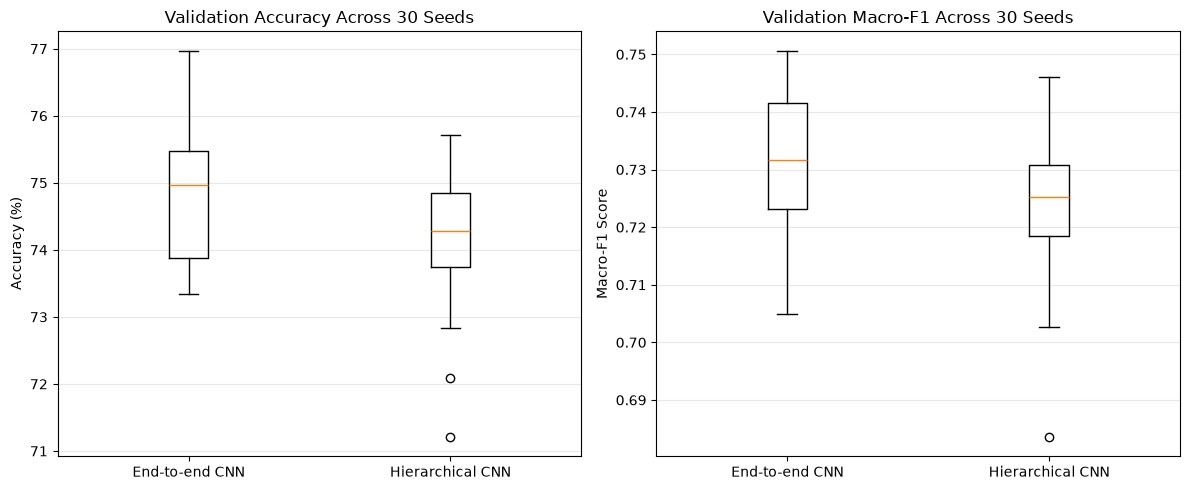

In [40]:
# Compare validation accuracy and macro-F1 across 30 matched seeds

import matplotlib.pyplot as plt
import pandas as pd

# Load the saved experiment results
results_df = pd.read_csv("repeated_experiment_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Validation accuracy
axes[0].boxplot(
    [
        results_df["baseline_accuracy"] * 100,
        results_df["hierarchical_accuracy"] * 100
    ],
    tick_labels=["End-to-end CNN", "Hierarchical CNN"]
)

axes[0].set_title("Validation Accuracy Across 30 Seeds")
axes[0].set_ylabel("Accuracy (%)")
axes[0].grid(axis="y", alpha=0.3)

# Plot 2: Macro-F1 score
axes[1].boxplot(
    [
        results_df["baseline_macro_f1"],
        results_df["hierarchical_macro_f1"]
    ],
    tick_labels=["End-to-end CNN", "Hierarchical CNN"]
)

axes[1].set_title("Validation Macro-F1 Across 30 Seeds")
axes[1].set_ylabel("Macro-F1 Score")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_performance_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

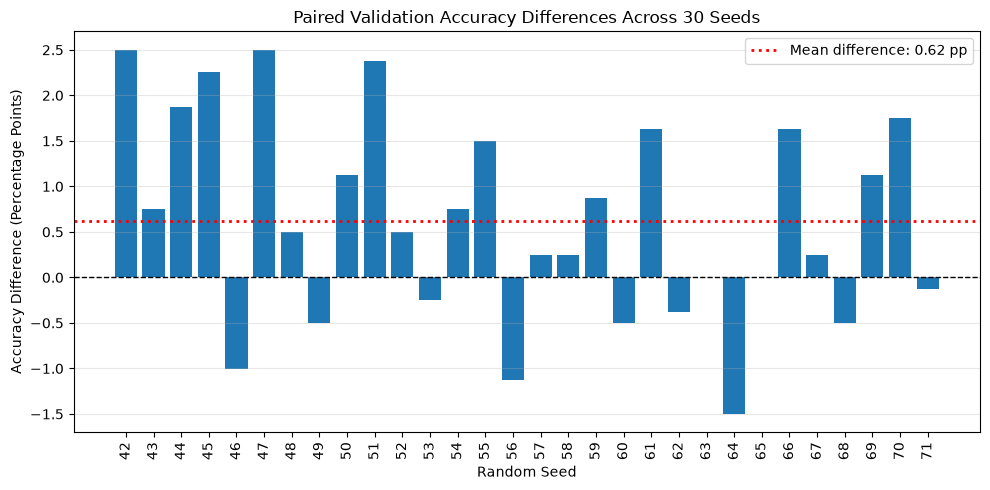

In [41]:
# Visualise accuracy differences for each matched random seed
# Positive values mean the end-to-end CNN performed better

accuracy_difference = (
    results_df["baseline_accuracy"]
    - results_df["hierarchical_accuracy"]
) * 100

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["seed"].astype(str),
    accuracy_difference
)

# Zero represents equal performance
plt.axhline(0, color="black", linestyle="--", linewidth=1)

# Mean difference across all seeds
plt.axhline(
    accuracy_difference.mean(),
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Mean difference: {accuracy_difference.mean():.2f} pp"
)

plt.title("Paired Validation Accuracy Differences Across 30 Seeds")
plt.xlabel("Random Seed")
plt.ylabel("Accuracy Difference (Percentage Points)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_paired_accuracy_differences.png", dpi=300, bbox_inches="tight")
plt.show()

### Paired Statistical Tests

In [42]:
# Statistical comparison using matched random seeds
# Positive differences favour the end-to-end CNN

from scipy import stats
import numpy as np

metrics = {
    "Accuracy": ("baseline_accuracy", "hierarchical_accuracy"),
    "Macro-F1": ("baseline_macro_f1", "hierarchical_macro_f1"),
}

for metric_name, (baseline_col, hierarchical_col) in metrics.items():

    baseline_values = results_df[baseline_col].to_numpy()
    hierarchical_values = results_df[hierarchical_col].to_numpy()

    differences = baseline_values - hierarchical_values

    # Paired t-test: each seed is compared against itself
    t_statistic, p_value = stats.ttest_rel(
        baseline_values,
        hierarchical_values
    )

    # 95% confidence interval for the mean paired difference
    mean_difference = differences.mean()
    standard_error = stats.sem(differences)

    confidence_interval = stats.t.interval(
        confidence=0.95,
        df=len(differences) - 1,
        loc=mean_difference,
        scale=standard_error
    )

    # Convert accuracy differences to percentage points
    scale = 100 if metric_name == "Accuracy" else 1

    print(f"\n{metric_name}")
    print(f"Mean paired difference: {mean_difference * scale:.4f}")
    print(f"t-statistic: {t_statistic:.4f}")
    print(f"p-value: {p_value:.6f}")
    print(
        "95% CI: "
        f"[{confidence_interval[0] * scale:.4f}, "
        f"{confidence_interval[1] * scale:.4f}]"
    )


Accuracy
Mean paired difference: 0.6174
t-statistic: 3.0108
p-value: 0.005353
95% CI: [0.1980, 1.0369]

Macro-F1
Mean paired difference: 0.0063
t-statistic: 2.2824
p-value: 0.029982
95% CI: [0.0007, 0.0119]


### Hierarchical Error Propagation Analysis

Total hierarchical errors: 6183
Task 1 errors: 4913 (79.46%)
Task 2 errors: 1270 (20.54%)

Mean hierarchical accuracy: 74.21%
Mean oracle-routing accuracy: 94.05%
Mean oracle-routing gain: 19.85 percentage points


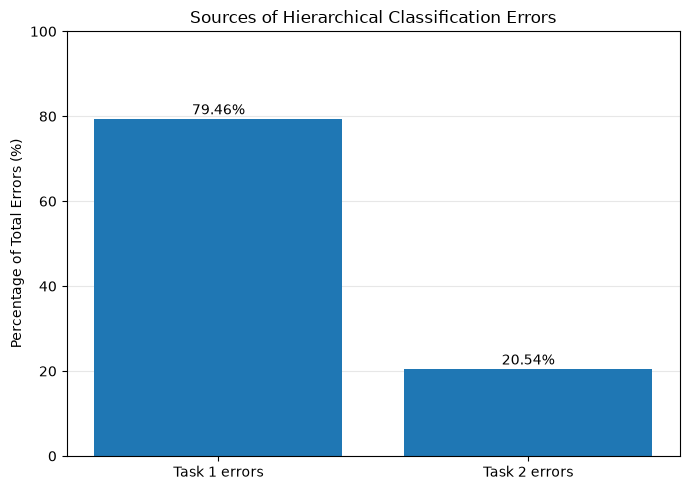

In [43]:
# Analyse the origin of hierarchical classification errors
# across all 30 matched-seed experiments

task1_total = results_df["task1_errors"].sum()
task2_total = results_df["task2_errors"].sum()
total_errors = results_df["total_errors"].sum()

# Verify the error decomposition is consistent
assert task1_total + task2_total == total_errors

task1_percentage = (task1_total / total_errors) * 100
task2_percentage = (task2_total / total_errors) * 100

mean_oracle_accuracy = results_df["oracle_accuracy"].mean() * 100
mean_hierarchical_accuracy = results_df["hierarchical_accuracy"].mean() * 100
mean_oracle_gain = results_df["oracle_gain"].mean() * 100

print(f"Total hierarchical errors: {total_errors}")
print(f"Task 1 errors: {task1_total} ({task1_percentage:.2f}%)")
print(f"Task 2 errors: {task2_total} ({task2_percentage:.2f}%)")

print(f"\nMean hierarchical accuracy: {mean_hierarchical_accuracy:.2f}%")
print(f"Mean oracle-routing accuracy: {mean_oracle_accuracy:.2f}%")
print(f"Mean oracle-routing gain: {mean_oracle_gain:.2f} percentage points")

# Visualise the error decomposition
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Task 1 errors", "Task 2 errors"],
    [task1_percentage, task2_percentage]
)

ax.set_title("Sources of Hierarchical Classification Errors")
ax.set_ylabel("Percentage of Total Errors (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for bar, percentage in zip(bars, [task1_percentage, task2_percentage]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("hierarchical_error_propagation.png", dpi=300, bbox_inches="tight")
plt.show()

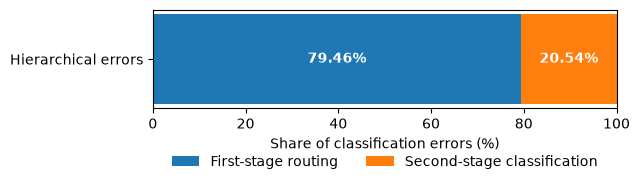

In [44]:
# Error-propagation plot

results_df = pd.read_csv("repeated_experiment_results.csv")

task1 = int(results_df["task1_errors"].sum())
task2 = int(results_df["task2_errors"].sum())
total = task1 + task2

fig, ax = plt.subplots(figsize=(6.5, 2.2))

ax.barh(
    ["Hierarchical errors"],
    [task1 / total * 100],
    label="First-stage routing",
)
ax.barh(
    ["Hierarchical errors"],
    [task2 / total * 100],
    left=[task1 / total * 100],
    label="Second-stage classification",
)

ax.text(task1 / total * 50, 0,
        f"{task1 / total * 100:.2f}%",
        ha="center", va="center", color="white", weight="bold")

ax.text(task1 / total * 100 + task2 / total * 50, 0,
        f"{task2 / total * 100:.2f}%",
        ha="center", va="center", color="white", weight="bold")

ax.set_xlim(0, 100)
ax.set_xlabel("Share of classification errors (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=2, frameon=False)

plt.tight_layout()
plt.savefig("hierarchical_error_propagation.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Computational Cost Comparison

Mean training time:
End-to-end CNN: 77.13 ± 1.68 seconds
Hierarchical CNN: 78.48 ± 1.09 seconds

Trainable parameters:
End-to-end CNN: 548,387
Hierarchical CNN: 548,516


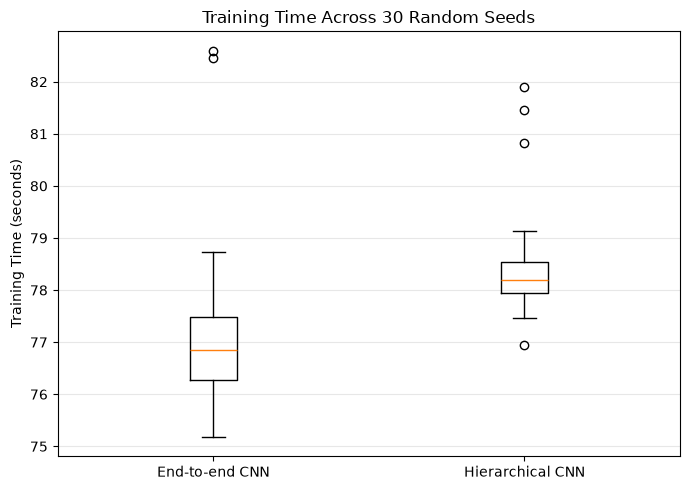

In [45]:
# Compare training time and model parameter counts

# Training time across 30 matched seeds
baseline_times = results_df["baseline_training_time"]
hierarchical_times = results_df["hierarchical_training_time"]

print("Mean training time:")
print(
    f"End-to-end CNN: "
    f"{baseline_times.mean():.2f} ± {baseline_times.std(ddof=1):.2f} seconds"
)
print(
    f"Hierarchical CNN: "
    f"{hierarchical_times.mean():.2f} ± {hierarchical_times.std(ddof=1):.2f} seconds"
)

# Count trainable parameters in each architecture
baseline_model = GalaxyCNN()
hierarchical_model = HierarchicalGalaxyCNN()

baseline_parameters = sum(
    p.numel() for p in baseline_model.parameters() if p.requires_grad
)

hierarchical_parameters = sum(
    p.numel() for p in hierarchical_model.parameters() if p.requires_grad
)

print("\nTrainable parameters:")
print(f"End-to-end CNN: {baseline_parameters:,}")
print(f"Hierarchical CNN: {hierarchical_parameters:,}")

# Plot training time distributions
plt.figure(figsize=(7, 5))

plt.boxplot(
    [baseline_times, hierarchical_times],
    tick_labels=["End-to-end CNN", "Hierarchical CNN"]
)

plt.title("Training Time Across 30 Random Seeds")
plt.ylabel("Training Time (seconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_training_time_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### Final Held-Out Test Evaluation

In [46]:
# Select a representative seed based only on validation results
# The held-out test set is not used for seed selection

paired_differences = (
    results_df["baseline_accuracy"]
    - results_df["hierarchical_accuracy"]
)

mean_difference = paired_differences.mean()

representative_index = (
    (paired_differences - mean_difference).abs().idxmin()
)

selected_seed = int(results_df.loc[representative_index, "seed"])

print(f"Selected representative seed: {selected_seed}")
print(f"Mean validation accuracy difference: {mean_difference * 100:.4f} pp")
print(
    "Selected seed accuracy difference: "
    f"{paired_differences.loc[representative_index] * 100:.4f} pp"
)

Selected representative seed: 48
Mean validation accuracy difference: 0.6174 pp
Selected seed accuracy difference: 0.5006 pp


In [47]:
# Retrain both CNNs using the representative seed selected
# from validation results only

print(f"Retraining both models with seed {selected_seed}...")

final_baseline_run = train_baseline(seed=selected_seed)
final_hierarchical_run = train_hierarchical(seed=selected_seed)

print("\nRetraining complete!")
print(f"End-to-end best epoch: {final_baseline_run['best_epoch']}")
print(f"Hierarchical best epoch: {final_hierarchical_run['best_epoch']}")

Retraining both models with seed 48...

Retraining complete!
End-to-end best epoch: 8
Hierarchical best epoch: 8


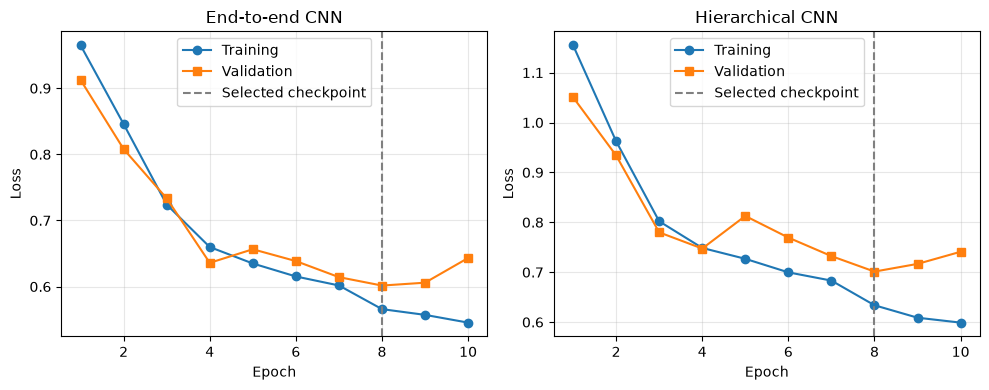

In [48]:
# Learning-curve figure generation

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

runs = [
    ("End-to-end CNN", final_baseline_run),
    ("Hierarchical CNN", final_hierarchical_run),
]

for ax, (name, run) in zip(axes, runs):
    epochs = range(1, len(run["train_losses"]) + 1)

    ax.plot(epochs, run["train_losses"], marker="o", label="Training")
    ax.plot(epochs, run["validation_losses"], marker="s", label="Validation")
    ax.axvline(run["best_epoch"], linestyle="--",
               color="gray", label="Selected checkpoint")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Final held-out test evaluation for both CNNs
# Uses the models selected through validation only

def evaluate_final_test(baseline_model, hierarchical_model):
    baseline_model.eval()
    hierarchical_model.eval()

    true_labels = []
    baseline_predictions = []
    hierarchical_predictions = []
    oracle_predictions = []

    task1_errors = 0
    task2_errors = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            # End-to-end CNN predictions
            baseline_outputs = baseline_model(images)
            baseline_preds = baseline_outputs.argmax(dim=1)

            # Hierarchical CNN predictions
            task1_outputs, task2_outputs = hierarchical_model(images)

            task1_preds = task1_outputs.argmax(dim=1)
            task2_preds = task2_outputs.argmax(dim=1)

            # Task 1: 0 = smooth, 1 = featured
            # Task 2: 0 = edge-on, 1 = not edge-on
            hierarchical_preds = torch.where(
                task1_preds == 0,
                0,
                task2_preds + 1
            )

            # Oracle routing: use the TRUE Task 1 decision
            # This is diagnostic, not a deployable prediction
            true_task1 = (labels != 0).long()

            oracle_preds = torch.where(
                true_task1 == 0,
                0,
                task2_preds + 1
            )

            # Decompose final hierarchical errors
            task1_wrong = task1_preds != true_task1
            task2_wrong = (
                (~task1_wrong)
                & (hierarchical_preds != labels)
            )

            task1_errors += task1_wrong.sum().item()
            task2_errors += task2_wrong.sum().item()

            true_labels.extend(labels.cpu().tolist())
            baseline_predictions.extend(baseline_preds.cpu().tolist())
            hierarchical_predictions.extend(hierarchical_preds.cpu().tolist())
            oracle_predictions.extend(oracle_preds.cpu().tolist())

    baseline_accuracy = accuracy_score(
        true_labels, baseline_predictions
    )
    baseline_f1 = f1_score(
        true_labels, baseline_predictions, average="macro"
    )

    hierarchical_accuracy = accuracy_score(
        true_labels, hierarchical_predictions
    )
    hierarchical_f1 = f1_score(
        true_labels, hierarchical_predictions, average="macro"
    )

    oracle_accuracy = accuracy_score(
        true_labels, oracle_predictions
    )

    total_errors = sum(
        true != pred
        for true, pred in zip(true_labels, hierarchical_predictions)
    )

    assert task1_errors + task2_errors == total_errors

    return {
        "baseline_accuracy": baseline_accuracy,
        "baseline_macro_f1": baseline_f1,
        "hierarchical_accuracy": hierarchical_accuracy,
        "hierarchical_macro_f1": hierarchical_f1,
        "task1_errors": task1_errors,
        "task2_errors": task2_errors,
        "total_errors": total_errors,
        "oracle_accuracy": oracle_accuracy,
        "oracle_gain": oracle_accuracy - hierarchical_accuracy,
    }


# Evaluate the retrained models on the untouched test set
final_test_results = evaluate_final_test(
    final_baseline_run["model"],
    final_hierarchical_run["model"]
)

print(f"Final held-out test results (seed {selected_seed})")
print("-" * 45)

print(f"End-to-end accuracy: {final_test_results['baseline_accuracy']:.4f}")
print(f"End-to-end macro-F1: {final_test_results['baseline_macro_f1']:.4f}")

print(f"Hierarchical accuracy: {final_test_results['hierarchical_accuracy']:.4f}")
print(f"Hierarchical macro-F1: {final_test_results['hierarchical_macro_f1']:.4f}")

print(f"\nTask 1 errors: {final_test_results['task1_errors']}")
print(f"Task 2 errors: {final_test_results['task2_errors']}")
print(f"Total hierarchical errors: {final_test_results['total_errors']}")

print(f"\nOracle-routing accuracy: {final_test_results['oracle_accuracy']:.4f}")
print(f"Oracle-routing gain: {final_test_results['oracle_gain'] * 100:.2f} pp")

Final held-out test results (seed 48)
---------------------------------------------
End-to-end accuracy: 0.7357
End-to-end macro-F1: 0.7214
Hierarchical accuracy: 0.7247
Hierarchical macro-F1: 0.7157

Task 1 errors: 225
Task 2 errors: 50
Total hierarchical errors: 275

Oracle-routing accuracy: 0.9409
Oracle-routing gain: 21.62 pp


In [117]:
# Save the final held-out test results for the report

final_test_df = pd.DataFrame([{
    "seed": selected_seed,
    **final_test_results
}])

final_test_df.to_csv("final_test_results.csv", index=False)

print("Saved final_test_results.csv")
print(final_test_df.to_string(index=False))

Saved final_test_results.csv
 seed  baseline_accuracy  baseline_macro_f1  hierarchical_accuracy  hierarchical_macro_f1  task1_errors  task2_errors  total_errors  oracle_accuracy  oracle_gain
   48           0.735736           0.721364               0.724725                0.71569           225            50           275         0.940941     0.216216
